In [4]:
import pandas as pd
import pathlib
from pathlib import Path

In [5]:
data_path = Path("/Users/patrykksiazek/Desktop/Machine-Learning---Preliminary-Data-Analysis/")

In [6]:
train_logs = pd.read_csv(data_path / "train_logs.csv")

In [7]:
train_logs.head(10)

,id,event_id,down_time,up_time,action_time,activity,down_event,up_event,text_change,cursor_position,word_count
0,001519c8,1,4526,4557,31,Nonproduction,Leftclick,Leftclick,NoChange,0,0
1,001519c8,2,4558,4962,404,Nonproduction,Leftclick,Leftclick,NoChange,0,0
2,001519c8,3,106571,106571,0,Nonproduction,Shift,Shift,NoChange,0,0
3,001519c8,4,106686,106777,91,Input,q,q,q,1,1
4,001519c8,5,107196,107323,127,Input,q,q,q,2,1
5,001519c8,6,107296,107400,104,Input,q,q,q,3,1
6,001519c8,7,107469,107596,127,Input,q,q,q,4,1
7,001519c8,8,107659,107766,107,Input,q,q,q,5,1
8,001519c8,9,107743,107852,109,Input,q,q,q,6,1
9,001519c8,10,107840,107978,138,Input,Space,Space,,7,1


In [8]:
chars_per_essay = train_logs[train_logs['activity'] == 'Input'].groupby('id').agg(
    chars_per_essay=('event_id', 'nunique')
    )

In [9]:
chars_per_essay

,chars_per_essay
id,
001519c8,2010
0022f953,1938
0042269b,3515
0059420b,1304
0075873a,1942
...,...
ffb8c745,3588
ffbef7e5,2395
ffccd6fd,2849


In [10]:
grouped_train_logs = train_logs.groupby('id').agg(
    words_per_essay=('word_count', 'last'),
    max_up_time=('up_time', 'max'),
    min_down_time=('down_time', 'min'),
    events_per_essay=('event_id', 'nunique')
)

In [11]:
grouped_train_logs

,words_per_essay,max_up_time,min_down_time,events_per_essay
id,,,,
001519c8,255,1801969,4526,2557
0022f953,320,1788969,30623,2454
0042269b,404,1771669,4441,4136
0059420b,206,1404469,41395,1556
0075873a,252,1662472,78470,2531
...,...,...,...,...
ffb8c745,273,1791649,22467,4739
ffbef7e5,438,1799174,21732,2604
ffccd6fd,201,1959363,23482,3063


In [12]:
grouped_train_logs['writing_duration'] = grouped_train_logs['max_up_time'] - grouped_train_logs['min_down_time']

In [13]:
grouped_train_logs = grouped_train_logs.merge(chars_per_essay, left_index=True, right_index=True)

In [14]:
grouped_train_logs['chars_per_minute'] = 1000 * 60 * grouped_train_logs['chars_per_essay'] / grouped_train_logs['writing_duration']

In [15]:
train_logs.sort_values(by=['id', 'down_time'], inplace=True)

train_logs['pause_time'] = (train_logs.groupby('id')['down_time'].shift(0) - train_logs.groupby('id')['up_time'].shift(1)).fillna(0)

In [16]:
train_logs['is_pause'] = train_logs['pause_time'] > 2000
train_logs['long_pause_time'] = train_logs['pause_time'].where(train_logs['is_pause'], 0)

In [17]:
pause_features = train_logs.groupby('id').agg(
    total_pauses=('is_pause', 'sum'),
    total_pause_time=('long_pause_time', 'sum')
)

In [18]:
pause_features

,total_pauses,total_pause_time
id,,
001519c8,124,1182600.0
0022f953,80,1174268.0
0042269b,77,1111167.0
0059420b,87,768075.0
0075873a,88,1045463.0
...,...,...
ffb8c745,41,967796.0
ffbef7e5,90,969383.0
ffccd6fd,87,1139801.0


In [19]:
stale_pause_columns = [
    column for column in grouped_train_logs.columns
    if column.startswith(("total_pauses", "total_pause_time"))
]
grouped_train_logs = grouped_train_logs.drop(columns=stale_pause_columns).join(
    pause_features, how="left"
)

In [20]:
grouped_train_logs

,words_per_essay,max_up_time,min_down_time,events_per_essay,writing_duration,chars_per_essay,chars_per_minute,total_pauses,total_pause_time
id,,,,,,,,,
001519c8,255,1801969,4526,2557,1797443,2010,67.095313,124,1182600.0
0022f953,320,1788969,30623,2454,1758346,1938,66.130329,80,1174268.0
0042269b,404,1771669,4441,4136,1767228,3515,119.339440,77,1111167.0
0059420b,206,1404469,41395,1556,1363074,1304,57.399672,87,768075.0
0075873a,252,1662472,78470,2531,1584002,1942,73.560513,88,1045463.0
...,...,...,...,...,...,...,...,...,...
ffb8c745,273,1791649,22467,4739,1769182,3588,121.683354,41,967796.0
ffbef7e5,438,1799174,21732,2604,1777442,2395,80.846520,90,969383.0
ffccd6fd,201,1959363,23482,3063,1935881,2849,88.300882,87,1139801.0


In [21]:
grouped_train_logs['perc_pause_time'] = grouped_train_logs['total_pause_time'] / grouped_train_logs['writing_duration']

In [22]:
grouped_train_logs['pauses_per_words'] = grouped_train_logs['total_pauses'] / grouped_train_logs['words_per_essay']

## Aktywności

In [23]:
train_logs['activity'].value_counts()

activity
Input                                     6726796
Remove/Cut                                 970158
Nonproduction                              703851
Replace                                      4448
Paste                                         599
Move From [1306, 1371] To [1061, 1126]          2
Move From [13, 65] To [9, 61]                   1
Move From [274, 314] To [299, 339]              1
Move From [624, 625] To [845, 846]              1
Move From [1861, 2063] To [1766, 1968]          1
Move From [1766, 1968] To [1861, 2063]          1
Move From [2091, 2179] To [252, 340]            1
Move From [923, 1077] To [340, 494]             1
Move From [0, 1] To [590, 591]                  1
Move From [999, 1000] To [1000, 1001]           1
Move From [0, 75] To [1, 76]                    1
Move From [1651, 1769] To [1565, 1683]          1
Move From [61, 136] To [0, 75]                  1
Move From [623, 632] To [624, 633]              1
Move From [75, 134] To [304, 363]        

In [24]:
train_logs['text_change_len'] = train_logs['text_change'].str.len()

In [25]:
train_logs.loc[train_logs['text_change'] == 'NoChange', 'text_change_len'] = 0

In [26]:
train_logs

,id,event_id,down_time,up_time,action_time,activity,down_event,up_event,text_change,cursor_position,word_count,pause_time,is_pause,long_pause_time,text_change_len
0,001519c8,1,4526,4557,31,Nonproduction,Leftclick,Leftclick,NoChange,0,0,0.0,False,0.0,0
1,001519c8,2,4558,4962,404,Nonproduction,Leftclick,Leftclick,NoChange,0,0,1.0,False,0.0,0
2,001519c8,3,106571,106571,0,Nonproduction,Shift,Shift,NoChange,0,0,101609.0,True,101609.0,0
3,001519c8,4,106686,106777,91,Input,q,q,q,1,1,115.0,False,0.0,1
4,001519c8,5,107196,107323,127,Input,q,q,q,2,1,419.0,False,0.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8405893,fff05981,3615,2063944,2064440,496,Nonproduction,Leftclick,Leftclick,NoChange,1031,240,1389.0,False,0.0,0
8405894,fff05981,3616,2064497,2064497,0,Nonproduction,Shift,Shift,NoChange,1031,240,57.0,False,0.0,0
8405895,fff05981,3617,2064657,2064765,108,Replace,q,q,q => q,1031,240,160.0,False,0.0,6
8405896,fff05981,3618,2069186,2069259,73,Nonproduction,Leftclick,Leftclick,NoChange,1028,240,4421.0,True,4421.0,0


In [27]:
activity_per_essay = {}
activites = ['Remove/Cut', 'Nonproduction', 'Replace', 'Paste']

for act in activites:
    activity_per_essay[act] = train_logs[train_logs['activity'] == act].groupby('id').agg(
        activity_per_essay=('event_id', 'nunique'),
        activity_len_per_essay=('text_change_len', 'sum')

    )

In [28]:
activity_per_essay['Remove/Cut']

,activity_per_essay,activity_len_per_essay
id,,
001519c8,417,417
0022f953,260,260
0042269b,439,632
0059420b,151,151
0075873a,517,517
...,...,...
ffb8c745,960,962
ffbef7e5,60,60
ffccd6fd,88,88


In [29]:
for act in activites:
    grouped_train_logs = grouped_train_logs.merge(activity_per_essay[act],
                                                  left_index=True,
                                                  right_index=True,
                                                  suffixes=('', f"_{act}"), how='left')

In [30]:
grouped_train_logs

,words_per_essay,max_up_time,min_down_time,events_per_essay,writing_duration,chars_per_essay,chars_per_minute,total_pauses,total_pause_time,perc_pause_time,pauses_per_words,activity_per_essay,activity_len_per_essay,activity_per_essay_Nonproduction,activity_len_per_essay_Nonproduction,activity_per_essay_Replace,activity_len_per_essay_Replace,activity_per_essay_Paste,activity_len_per_essay_Paste
id,,,,,,,,,,,,,,,,,,,
001519c8,255,1801969,4526,2557,1797443,2010,67.095313,124,1182600.0,0.657935,0.486275,417.0,417.0,120,0,7.0,107.0,NaN,NaN
0022f953,320,1788969,30623,2454,1758346,1938,66.130329,80,1174268.0,0.667825,0.250000,260.0,260.0,254,0,1.0,11.0,1.0,2.0
0042269b,404,1771669,4441,4136,1767228,3515,119.339440,77,1111167.0,0.628763,0.190594,439.0,632.0,175,0,7.0,338.0,NaN,NaN
0059420b,206,1404469,41395,1556,1363074,1304,57.399672,87,768075.0,0.563487,0.422330,151.0,151.0,99,0,1.0,17.0,1.0,12.0
0075873a,252,1662472,78470,2531,1584002,1942,73.560513,88,1045463.0,0.660014,0.349206,517.0,517.0,72,0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ffb8c745,273,1791649,22467,4739,1769182,3588,121.683354,41,967796.0,0.547030,0.150183,960.0,962.0,189,0,2.0,1004.0,NaN,NaN
ffbef7e5,438,1799174,21732,2604,1777442,2395,80.846520,90,969383.0,0.545381,0.205479,60.0,60.0,148,0,1.0,6.0,NaN,NaN
ffccd6fd,201,1959363,23482,3063,1935881,2849,88.300882,87,1139801.0,0.588776,0.432836,88.0,88.0,126,0,NaN,NaN,NaN,NaN


In [31]:
grouped_train_logs.rename(columns={'activity_per_essay': 'removes_per_essay',
                                   'activity_len_per_essay': 'removes_len_per_essay'}, inplace=True)

In [32]:
grouped_train_logs['removes_per_words'] = grouped_train_logs['removes_per_essay'] / grouped_train_logs['words_per_essay']

In [33]:
grouped_train_logs['replaces_per_words'] = grouped_train_logs['activity_per_essay_Replace'] / grouped_train_logs['words_per_essay']

In [34]:
grouped_train_logs.fillna(0, inplace=True)

In [35]:
grouped_train_logs.to_csv(data_path / 'grouped_train_logs.csv')

## Analiza

In [36]:
try:
    from ydata_profiling import ProfileReport
except ModuleNotFoundError as error:
    if error.name != "ydata_profiling":
        raise
    profile_available = False
    print("Optional profiling skipped. Install ydata-profiling to generate the report.")
else:
    profile_available = True

Optional profiling skipped. Install ydata-profiling to generate the report.


In [37]:
if profile_available:
    profile = ProfileReport(grouped_train_logs, title='Profiling Report')

In [38]:
if profile_available:
    from IPython.display import display
    display(profile)

## Zaawansowane cechy

In [39]:
grouped_train_logs['chars_per_words'] = grouped_train_logs['chars_per_essay'] / grouped_train_logs ['words_per_essay']

In [40]:
grouped_train_logs.reset_index(inplace=True)

In [41]:
grouped_train_logs

,id,words_per_essay,max_up_time,min_down_time,events_per_essay,writing_duration,chars_per_essay,chars_per_minute,total_pauses,total_pause_time,...,removes_len_per_essay,activity_per_essay_Nonproduction,activity_len_per_essay_Nonproduction,activity_per_essay_Replace,activity_len_per_essay_Replace,activity_per_essay_Paste,activity_len_per_essay_Paste,removes_per_words,replaces_per_words,chars_per_words
0,001519c8,255,1801969,4526,2557,1797443,2010,67.095313,124,1182600.0,...,417.0,120,0,7.0,107.0,0.0,0.0,1.635294,0.027451,7.882353
1,0022f953,320,1788969,30623,2454,1758346,1938,66.130329,80,1174268.0,...,260.0,254,0,1.0,11.0,1.0,2.0,0.812500,0.003125,6.056250
2,0042269b,404,1771669,4441,4136,1767228,3515,119.339440,77,1111167.0,...,632.0,175,0,7.0,338.0,0.0,0.0,1.086634,0.017327,8.700495
3,0059420b,206,1404469,41395,1556,1363074,1304,57.399672,87,768075.0,...,151.0,99,0,1.0,17.0,1.0,12.0,0.733010,0.004854,6.330097
4,0075873a,252,1662472,78470,2531,1584002,1942,73.560513,88,1045463.0,...,517.0,72,0,0.0,0.0,0.0,0.0,2.051587,0.000000,7.706349
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2466,ffb8c745,273,1791649,22467,4739,1769182,3588,121.683354,41,967796.0,...,962.0,189,0,2.0,1004.0,0.0,0.0,3.516484,0.007326,13.142857
2467,ffbef7e5,438,1799174,21732,2604,1777442,2395,80.846520,90,969383.0,...,60.0,148,0,1.0,6.0,0.0,0.0,0.136986,0.002283,5.468037
2468,ffccd6fd,201,1959363,23482,3063,1935881,2849,88.300882,87,1139801.0,...,88.0,126,0,0.0,0.0,0.0,0.0,0.437811,0.000000,14.174129
2469,ffec5b38,413,1508504,19885,3242,1488619,2895,116.685330,63,738365.0,...,343.0,71,0,0.0,0.0,0.0,0.0,0.668281,0.000000,7.009685


In [42]:
train_logs = train_logs.merge(grouped_train_logs[['id', 'min_down_time', 'writing_duration', 'words_per_essay']], on='id', how='left')

In [45]:
train_logs['perc_time'] = (train_logs['up_time'] - train_logs['min_down_time']) / train_logs['writing_duration']
train_logs['perc_words'] = (train_logs['word_count'] / train_logs['words_per_essay'])

In [47]:
from tqdm import tqdm
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


100%|██████████| 50/50 [00:30<00:00,  1.63it/s]


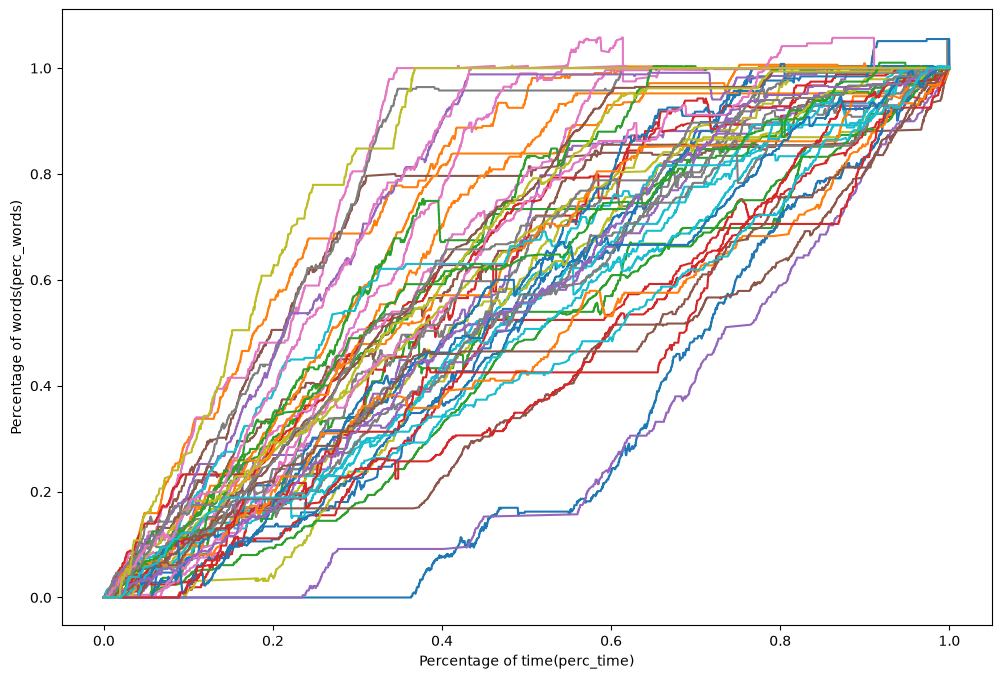

In [48]:
unique_ids = train_logs['id'].unique()

plt.figure(figsize=(12, 8))

for uid in tqdm (unique_ids[:50]):
    subset= train_logs[train_logs['id'] == uid]
    plt.plot(subset['perc_time'], subset['perc_words'], label=uid)

plt.xlabel(('Percentage of time(perc_time)'))
plt.ylabel(('Percentage of words(perc_words)'))
plt.show()

In [50]:
thres_res = {}

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

for t in thresholds:
    subset = train_logs[train_logs['perc_words'] >= t]
    subset = pd.DataFrame(subset.groupby('id')['perc_time'].min())
    thres_res[t] = subset

In [53]:
thres_tab = thres_res[thresholds[0]][['perc_time']].rename(
    columns={'perc_time': f'perc_time_{thresholds[0]}'})

for t in thresholds[1:]:
    thres_tab = thres_tab.merge(
        thres_res[t][['perc_time']].rename(columns={'perc_time': f'perc_time_{t}'}),
        left_index=True, right_index=True)


In [54]:
thres_tab

,perc_time_0.1,perc_time_0.2,perc_time_0.3,perc_time_0.4,perc_time_0.5,perc_time_0.6,perc_time_0.7,perc_time_0.8,perc_time_0.9
id,,,,,,,,,
001519c8,0.155143,0.293721,0.359292,0.404129,0.464780,0.516710,0.618676,0.651854,0.721284
0022f953,0.037671,0.069788,0.100188,0.145902,0.177045,0.219058,0.317932,0.383138,0.460980
0042269b,0.122482,0.209564,0.232540,0.316556,0.370777,0.610536,0.790196,0.820712,0.903792
0059420b,0.150942,0.287772,0.363529,0.412877,0.452492,0.672673,0.734661,0.830656,0.917422
0075873a,0.079099,0.116387,0.273668,0.337919,0.411840,0.474403,0.500047,0.539487,0.736932
...,...,...,...,...,...,...,...,...,...
ffb8c745,0.017781,0.033713,0.069632,0.096697,0.110400,0.133427,0.161546,0.175222,0.246015
ffbef7e5,0.129672,0.194467,0.264695,0.339355,0.389790,0.452708,0.524862,0.827321,0.919629
ffccd6fd,0.045346,0.087770,0.204519,0.249888,0.435321,0.461315,0.517000,0.605986,0.656534


In [55]:
grouped_train_logs = grouped_train_logs.merge(thres_tab. reset_index(), on='id')

In [56]:
grouped_train_logs

,id,words_per_essay,max_up_time,min_down_time,events_per_essay,writing_duration,chars_per_essay,chars_per_minute,total_pauses,total_pause_time,...,chars_per_words,perc_time_0.1,perc_time_0.2,perc_time_0.3,perc_time_0.4,perc_time_0.5,perc_time_0.6,perc_time_0.7,perc_time_0.8,perc_time_0.9
0,001519c8,255,1801969,4526,2557,1797443,2010,67.095313,124,1182600.0,...,7.882353,0.155143,0.293721,0.359292,0.404129,0.464780,0.516710,0.618676,0.651854,0.721284
1,0022f953,320,1788969,30623,2454,1758346,1938,66.130329,80,1174268.0,...,6.056250,0.037671,0.069788,0.100188,0.145902,0.177045,0.219058,0.317932,0.383138,0.460980
2,0042269b,404,1771669,4441,4136,1767228,3515,119.339440,77,1111167.0,...,8.700495,0.122482,0.209564,0.232540,0.316556,0.370777,0.610536,0.790196,0.820712,0.903792
3,0059420b,206,1404469,41395,1556,1363074,1304,57.399672,87,768075.0,...,6.330097,0.150942,0.287772,0.363529,0.412877,0.452492,0.672673,0.734661,0.830656,0.917422
4,0075873a,252,1662472,78470,2531,1584002,1942,73.560513,88,1045463.0,...,7.706349,0.079099,0.116387,0.273668,0.337919,0.411840,0.474403,0.500047,0.539487,0.736932
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2466,ffb8c745,273,1791649,22467,4739,1769182,3588,121.683354,41,967796.0,...,13.142857,0.017781,0.033713,0.069632,0.096697,0.110400,0.133427,0.161546,0.175222,0.246015
2467,ffbef7e5,438,1799174,21732,2604,1777442,2395,80.846520,90,969383.0,...,5.468037,0.129672,0.194467,0.264695,0.339355,0.389790,0.452708,0.524862,0.827321,0.919629
2468,ffccd6fd,201,1959363,23482,3063,1935881,2849,88.300882,87,1139801.0,...,14.174129,0.045346,0.087770,0.204519,0.249888,0.435321,0.461315,0.517000,0.605986,0.656534
2469,ffec5b38,413,1508504,19885,3242,1488619,2895,116.685330,63,738365.0,...,7.009685,0.086481,0.150296,0.217490,0.290218,0.373499,0.437553,0.522221,0.586659,0.702237


## Burst

In [57]:
train_logs

,id,event_id,down_time,up_time,action_time,activity,down_event,up_event,text_change,cursor_position,word_count,pause_time,is_pause,long_pause_time,text_change_len,min_down_time,writing_duration,words_per_essay,perc_time,perc_words
0,001519c8,1,4526,4557,31,Nonproduction,Leftclick,Leftclick,NoChange,0,0,0.0,False,0.0,0,4526,1797443,255,0.000017,0.000000
1,001519c8,2,4558,4962,404,Nonproduction,Leftclick,Leftclick,NoChange,0,0,1.0,False,0.0,0,4526,1797443,255,0.000243,0.000000
2,001519c8,3,106571,106571,0,Nonproduction,Shift,Shift,NoChange,0,0,101609.0,True,101609.0,0,4526,1797443,255,0.056772,0.000000
3,001519c8,4,106686,106777,91,Input,q,q,q,1,1,115.0,False,0.0,1,4526,1797443,255,0.056887,0.003922
4,001519c8,5,107196,107323,127,Input,q,q,q,2,1,419.0,False,0.0,1,4526,1797443,255,0.057191,0.003922
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8405893,fff05981,3615,2063944,2064440,496,Nonproduction,Leftclick,Leftclick,NoChange,1031,240,1389.0,False,0.0,0,39727,2030406,240,0.997196,1.000000
8405894,fff05981,3616,2064497,2064497,0,Nonproduction,Shift,Shift,NoChange,1031,240,57.0,False,0.0,0,39727,2030406,240,0.997224,1.000000
8405895,fff05981,3617,2064657,2064765,108,Replace,q,q,q => q,1031,240,160.0,False,0.0,6,39727,2030406,240,0.997356,1.000000
8405896,fff05981,3618,2069186,2069259,73,Nonproduction,Leftclick,Leftclick,NoChange,1028,240,4421.0,True,4421.0,0,39727,2030406,240,0.999570,1.000000


In [58]:
train_logs['group'] = train_logs['is_pause'].cumsum().shift(fill_value=0)

In [59]:
train_logs

,id,event_id,down_time,up_time,action_time,activity,down_event,up_event,text_change,cursor_position,...,pause_time,is_pause,long_pause_time,text_change_len,min_down_time,writing_duration,words_per_essay,perc_time,perc_words,group
0,001519c8,1,4526,4557,31,Nonproduction,Leftclick,Leftclick,NoChange,0,...,0.0,False,0.0,0,4526,1797443,255,0.000017,0.000000,0
1,001519c8,2,4558,4962,404,Nonproduction,Leftclick,Leftclick,NoChange,0,...,1.0,False,0.0,0,4526,1797443,255,0.000243,0.000000,0
2,001519c8,3,106571,106571,0,Nonproduction,Shift,Shift,NoChange,0,...,101609.0,True,101609.0,0,4526,1797443,255,0.056772,0.000000,0
3,001519c8,4,106686,106777,91,Input,q,q,q,1,...,115.0,False,0.0,1,4526,1797443,255,0.056887,0.003922,1
4,001519c8,5,107196,107323,127,Input,q,q,q,2,...,419.0,False,0.0,1,4526,1797443,255,0.057191,0.003922,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8405893,fff05981,3615,2063944,2064440,496,Nonproduction,Leftclick,Leftclick,NoChange,1031,...,1389.0,False,0.0,0,39727,2030406,240,0.997196,1.000000,209221
8405894,fff05981,3616,2064497,2064497,0,Nonproduction,Shift,Shift,NoChange,1031,...,57.0,False,0.0,0,39727,2030406,240,0.997224,1.000000,209221
8405895,fff05981,3617,2064657,2064765,108,Replace,q,q,q => q,1031,...,160.0,False,0.0,6,39727,2030406,240,0.997356,1.000000,209221
8405896,fff05981,3618,2069186,2069259,73,Nonproduction,Leftclick,Leftclick,NoChange,1028,...,4421.0,True,4421.0,0,39727,2030406,240,0.999570,1.000000,209221


In [63]:
grouped = train_logs[~train_logs['is_pause'] & (train_logs['activity'] == 'Input')].groupby(['id','group'])

In [64]:
writing_time_no_pause = grouped['up_time'].last() - grouped['down_time'].first()

In [65]:
writing_time_no_pause

id        group 
001519c8  1         11549
          4         16393
          6          1852
          7          1902
          8          3528
                    ...  
fff05981  209217     9687
          209218     9740
          209219      508
          209220     1316
          209222       68
Length: 163025, dtype: int64

In [72]:
words_no_pause = grouped['word_count'].last() - grouped['word_count'].first() + 1

In [73]:
words_no_pause

id        group 
001519c8  1         12
          4          8
          6          1
          7          2
          8          1
                    ..
fff05981  209217     9
          209218     5
          209219     1
          209220     1
          209222     1
Name: word_count, Length: 163025, dtype: int64

In [74]:
combined = pd.DataFrame({
    'writing_time_no_pause': writing_time_no_pause,
    'words_no_pause': words_no_pause}).reset_index()

In [75]:
train_logs = train_logs.merge(combined, on=['id','group'], how='left')

In [70]:
train_logs

,id,event_id,down_time,up_time,action_time,activity,down_event,up_event,text_change,cursor_position,...,pause_time,is_pause,long_pause_time,text_change_len,min_down_time,writing_duration,words_per_essay,perc_time,perc_words,group
0,001519c8,1,4526,4557,31,Nonproduction,Leftclick,Leftclick,NoChange,0,...,0.0,False,0.0,0,4526,1797443,255,0.000017,0.000000,0
1,001519c8,2,4558,4962,404,Nonproduction,Leftclick,Leftclick,NoChange,0,...,1.0,False,0.0,0,4526,1797443,255,0.000243,0.000000,0
2,001519c8,3,106571,106571,0,Nonproduction,Shift,Shift,NoChange,0,...,101609.0,True,101609.0,0,4526,1797443,255,0.056772,0.000000,0
3,001519c8,4,106686,106777,91,Input,q,q,q,1,...,115.0,False,0.0,1,4526,1797443,255,0.056887,0.003922,1
4,001519c8,5,107196,107323,127,Input,q,q,q,2,...,419.0,False,0.0,1,4526,1797443,255,0.057191,0.003922,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8405893,fff05981,3615,2063944,2064440,496,Nonproduction,Leftclick,Leftclick,NoChange,1031,...,1389.0,False,0.0,0,39727,2030406,240,0.997196,1.000000,209221
8405894,fff05981,3616,2064497,2064497,0,Nonproduction,Shift,Shift,NoChange,1031,...,57.0,False,0.0,0,39727,2030406,240,0.997224,1.000000,209221
8405895,fff05981,3617,2064657,2064765,108,Replace,q,q,q => q,1031,...,160.0,False,0.0,6,39727,2030406,240,0.997356,1.000000,209221
8405896,fff05981,3618,2069186,2069259,73,Nonproduction,Leftclick,Leftclick,NoChange,1028,...,4421.0,True,4421.0,0,39727,2030406,240,0.999570,1.000000,209221


In [76]:
burst_tab = train_logs.groupby('id')[['words_no_pause','writing_time_no_pause']].max().reset_index()

In [77]:
burst_tab

,id,words_no_pause,writing_time_no_pause
0,001519c8,12.0,23678.0
1,0022f953,35.0,47943.0
2,0042269b,43.0,67797.0
3,0059420b,13.0,30814.0
4,0075873a,32.0,32599.0
...,...,...,...
2466,ffb8c745,80.0,103852.0
2467,ffbef7e5,36.0,64889.0
2468,ffccd6fd,29.0,67968.0
2469,ffec5b38,36.0,66817.0


In [78]:
n_bursts = train_logs.groupby('id')['group'].nunique()

In [79]:
burst_tab = burst_tab.merge(n_bursts.reset_index())

In [80]:
burst_tab

,id,words_no_pause,writing_time_no_pause,group
0,001519c8,12.0,23678.0,124
1,0022f953,35.0,47943.0,81
2,0042269b,43.0,67797.0,78
3,0059420b,13.0,30814.0,88
4,0075873a,32.0,32599.0,89
...,...,...,...,...
2466,ffb8c745,80.0,103852.0,42
2467,ffbef7e5,36.0,64889.0,91
2468,ffccd6fd,29.0,67968.0,87
2469,ffec5b38,36.0,66817.0,63


In [81]:
group_train_logs = grouped_train_logs.merge(burst_tab)

In [84]:
grouped_train_logs

,id,words_per_essay,max_up_time,min_down_time,events_per_essay,writing_duration,chars_per_essay,chars_per_minute,total_pauses,total_pause_time,...,chars_per_words,perc_time_0.1,perc_time_0.2,perc_time_0.3,perc_time_0.4,perc_time_0.5,perc_time_0.6,perc_time_0.7,perc_time_0.8,perc_time_0.9
0,001519c8,255,1801969,4526,2557,1797443,2010,67.095313,124,1182600.0,...,7.882353,0.155143,0.293721,0.359292,0.404129,0.464780,0.516710,0.618676,0.651854,0.721284
1,0022f953,320,1788969,30623,2454,1758346,1938,66.130329,80,1174268.0,...,6.056250,0.037671,0.069788,0.100188,0.145902,0.177045,0.219058,0.317932,0.383138,0.460980
2,0042269b,404,1771669,4441,4136,1767228,3515,119.339440,77,1111167.0,...,8.700495,0.122482,0.209564,0.232540,0.316556,0.370777,0.610536,0.790196,0.820712,0.903792
3,0059420b,206,1404469,41395,1556,1363074,1304,57.399672,87,768075.0,...,6.330097,0.150942,0.287772,0.363529,0.412877,0.452492,0.672673,0.734661,0.830656,0.917422
4,0075873a,252,1662472,78470,2531,1584002,1942,73.560513,88,1045463.0,...,7.706349,0.079099,0.116387,0.273668,0.337919,0.411840,0.474403,0.500047,0.539487,0.736932
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2466,ffb8c745,273,1791649,22467,4739,1769182,3588,121.683354,41,967796.0,...,13.142857,0.017781,0.033713,0.069632,0.096697,0.110400,0.133427,0.161546,0.175222,0.246015
2467,ffbef7e5,438,1799174,21732,2604,1777442,2395,80.846520,90,969383.0,...,5.468037,0.129672,0.194467,0.264695,0.339355,0.389790,0.452708,0.524862,0.827321,0.919629
2468,ffccd6fd,201,1959363,23482,3063,1935881,2849,88.300882,87,1139801.0,...,14.174129,0.045346,0.087770,0.204519,0.249888,0.435321,0.461315,0.517000,0.605986,0.656534
2469,ffec5b38,413,1508504,19885,3242,1488619,2895,116.685330,63,738365.0,...,7.009685,0.086481,0.150296,0.217490,0.290218,0.373499,0.437553,0.522221,0.586659,0.702237


In [86]:
grouped_train_logs['bursts_per_words'] = grouped_train_logs['group'] / grouped_train_logs['words_per_essay']
grouped_train_logs['words_no_pause_per_words'] = grouped_train_logs['words_no_pause'] / grouped_train_logs['words_per_essay']
grouped_train_logs['writing_time_no_pause_per_time'] = grouped_train_logs['writing_time_no_pause'] / grouped_train_logs['writing_time']

KeyError: 'group'

In [87]:
grouped_train_logs.to_csv(data_path/ 'grouped_train_logs_advanced.csv')